


<div align="center">

<h1 style="color:blue; font-weight:bold;">
Weather Data Auditing (HadUK-Grid weather data)
</h1>

</div>

### Step 1: Import Required Libraries

Import the libraries required to locate, load, and inspect the HadUK-Grid weather data. `pathlib` provides a reliable way to work with file paths, while `xarray` is designed to handle multidimensional scientific datasets stored in NetCDF format.

In [1]:
# pathlib helps us locate files using platform-independent paths.
from pathlib import Path

# xarray allows us to load and inspect multidimensional NetCDF datasets.
import xarray as xr

### Step 2: Locate and Verify the Monthly Weather Files

Identify the directories containing the 2025 daily rainfall and mean temperature data. Before loading the datasets, verify that each directory contains the expected 12 monthly NetCDF files. This check helps identify missing files or directory organization issues before proceeding with the analysis.

In [2]:
# Define the directories containing the monthly weather files.
rainfall_dir = Path("../data/weather/rainfall")
temperature_dir = Path("../data/weather/temperature")

# Sort the file paths to keep the monthly files in a consistent order.
rainfall_files = sorted(rainfall_dir.glob("*.nc"))
temperature_files = sorted(temperature_dir.glob("*.nc"))

# Display the number of files found to confirm the directory checks.
print("Rainfall files:", len(rainfall_files))
print("Temperature files:", len(temperature_files))

print("\nRainfall files:")
for file in rainfall_files:
    print(file.name)

print("\nTemperature files:")
for file in temperature_files:
    print(file.name)

Rainfall files: 12
Temperature files: 12

Rainfall files:
rainfall_hadukgrid_uk_5km_day_20250101-20250131.nc
rainfall_hadukgrid_uk_5km_day_20250201-20250228.nc
rainfall_hadukgrid_uk_5km_day_20250301-20250331.nc
rainfall_hadukgrid_uk_5km_day_20250401-20250430.nc
rainfall_hadukgrid_uk_5km_day_20250501-20250531.nc
rainfall_hadukgrid_uk_5km_day_20250601-20250630.nc
rainfall_hadukgrid_uk_5km_day_20250701-20250731.nc
rainfall_hadukgrid_uk_5km_day_20250801-20250831.nc
rainfall_hadukgrid_uk_5km_day_20250901-20250930.nc
rainfall_hadukgrid_uk_5km_day_20251001-20251031.nc
rainfall_hadukgrid_uk_5km_day_20251101-20251130.nc
rainfall_hadukgrid_uk_5km_day_20251201-20251231.nc

Temperature files:
tas_hadukgrid_uk_5km_day_20250101-20250131.nc
tas_hadukgrid_uk_5km_day_20250201-20250228.nc
tas_hadukgrid_uk_5km_day_20250301-20250331.nc
tas_hadukgrid_uk_5km_day_20250401-20250430.nc
tas_hadukgrid_uk_5km_day_20250501-20250531.nc
tas_hadukgrid_uk_5km_day_20250601-20250630.nc
tas_hadukgrid_uk_5km_day_20250701-

### Step 3: Load and Inspect the Weather Datasets

Load the monthly NetCDF files into two separate `xarray` datasets: one for rainfall and another for mean temperature. The `combine="by_coords"` argument allows `xarray` to combine the monthly files according to their coordinates, including time.

Inspect the resulting dataset dimensions to verify that the monthly files have been combined and that the expected temporal and spatial dimensions are present. This provides an initial structural check before auditing date coverage, coordinate alignment, variable units, and missing values.

In [3]:
# Combine the 12 monthly rainfall files using their coordinates.
rainfall_ds = xr.open_mfdataset(
    [str(f) for f in rainfall_files],
    combine="by_coords"
)

# Combine the 12 monthly mean temperature files in the same way.
temperature_ds = xr.open_mfdataset(
    [str(f) for f in temperature_files],
    combine="by_coords"
)

# Inspect the dimensions to check the time axis and spatial grid.
print("Rainfall dimensions:", rainfall_ds.sizes)
print("Temperature dimensions:", temperature_ds.sizes)

Rainfall dimensions: Frozen({'time': 365, 'projection_y_coordinate': 290, 'projection_x_coordinate': 180, 'bnds': 2})
Temperature dimensions: Frozen({'time': 365, 'projection_y_coordinate': 290, 'projection_x_coordinate': 180, 'bnds': 2})


### Step 4: Audit Dates, Coordinates, Units, and Missing Values

Before combining the rainfall and temperature variables, we need to verify the temporal coverage, spatial grid, measurement units, and data completeness of both datasets.

This audit helps identify missing dates, inconsistencies in spatial coordinates, unexpected measurement units, and missing observations that could affect subsequent analysis.

We will:
- Check the start and end dates and the number of daily observations.
- Verify that rainfall and temperature share the same time coordinates and spatial grid.
- Inspect the units and metadata of both variables to understand how measurements are represented.
- Count missing values to assess data completeness.

These checks will help determine whether the datasets are suitable for merging and further preprocessing.

In [4]:
# Inspect the time coverage and number of observations in each dataset.
# A complete daily dataset for 2025 should contain 365 observations.

for name, ds in [
    ("Rainfall", rainfall_ds),
    ("Temperature", temperature_ds)
]:
    print(f"\n{name} dataset")
    print("-" * 40)

    print("Start date:", ds.time.min().values)
    print("End date:", ds.time.max().values)
    print("Number of time observations:", ds.sizes["time"])

    # Check for duplicate dates that could cause problems during merging.
    time_index = ds.indexes["time"]
    print("Duplicate timestamps:", time_index.has_duplicates)


Rainfall dataset
----------------------------------------
Start date: 2025-01-01T12:00:00.000000000
End date: 2025-12-31T12:00:00.000000000
Number of time observations: 365
Duplicate timestamps: False

Temperature dataset
----------------------------------------
Start date: 2025-01-01T12:00:00.000000000
End date: 2025-12-31T12:00:00.000000000
Number of time observations: 365
Duplicate timestamps: False


In [5]:
# Compare the time coordinates to ensure both variables cover the same dates.
same_time = rainfall_ds.time.equals(temperature_ds.time)

# Compare the projected grid coordinates to confirm that both datasets
# represent the same spatial grid.
same_x = rainfall_ds.projection_x_coordinate.equals(
    temperature_ds.projection_x_coordinate
)

same_y = rainfall_ds.projection_y_coordinate.equals(
    temperature_ds.projection_y_coordinate
)

# Latitude and longitude are also checked because they identify
# the geographic locations represented by the grid cells.
same_latitude = rainfall_ds.latitude.equals(temperature_ds.latitude)
same_longitude = rainfall_ds.longitude.equals(temperature_ds.longitude)

print("Time coordinates match:", same_time)
print("Projected X coordinates match:", same_x)
print("Projected Y coordinates match:", same_y)
print("Latitude coordinates match:", same_latitude)
print("Longitude coordinates match:", same_longitude)

Time coordinates match: True
Projected X coordinates match: True
Projected Y coordinates match: True
Latitude coordinates match: True
Longitude coordinates match: True


In [6]:
# Inspect the metadata to understand the measurement units and
# definitions before interpreting or transforming the variables.

print("Rainfall variable metadata:")
print(rainfall_ds["rainfall"].attrs)

print("\nTemperature variable metadata:")
print(temperature_ds["tas"].attrs)

Rainfall variable metadata:
{'standard_name': 'lwe_thickness_of_precipitation_amount', 'long_name': 'Total rainfall', 'units': 'mm', 'description': 'Total rainfall', 'label_units': 'mm', 'level': 'NA', 'plot_label': 'Total rainfall (mm)', 'cell_methods': 'time: sum', 'grid_mapping': 'transverse_mercator'}

Temperature variable metadata:
{'standard_name': 'air_temperature', 'long_name': 'Mean air temperature', 'units': 'degC', 'description': 'Mean air temperature', 'label_units': '°C', 'level': '1.5m', 'plot_label': 'Mean air temperature at 1.5m (°C)', 'cell_methods': 'time: mid_range', 'grid_mapping': 'transverse_mercator'}


In [7]:
# Count missing values in each variable across all dates and grid cells.
# This helps quantify data completeness before further processing.

rainfall_missing = int(rainfall_ds["rainfall"].isnull().sum().compute().item())
temperature_missing = int(temperature_ds["tas"].isnull().sum().compute().item())

# Calculate the total number of observations in each variable.
rainfall_total = rainfall_ds["rainfall"].size
temperature_total = temperature_ds["tas"].size

# Express missing values as percentages for easier comparison.
rainfall_missing_pct = 100 * rainfall_missing / rainfall_total
temperature_missing_pct = 100 * temperature_missing / temperature_total

print("Rainfall missing values:", rainfall_missing)
print(f"Rainfall missing percentage: {rainfall_missing_pct:.4f}%")

print("\nTemperature missing values:", temperature_missing)
print(f"Temperature missing percentage: {temperature_missing_pct:.4f}%")

Rainfall missing values: 15245320
Rainfall missing percentage: 80.0153%

Temperature missing values: 15245320
Temperature missing percentage: 80.0153%


####   Interpretation of Step 4's Results:

| Check | Result | Interpretation |
|---|---|---|
| Temporal coverage | Jan 1 – Dec 31, 2025 | Full year covered |
| Daily observations | 365 per dataset | Expected for 2025 |
| Duplicate timestamps | None | No duplicate dates |
| Time coordinates | Match | Suitable for temporal alignment |
| Spatial coordinates | All match | Suitable for spatial alignment |
| Rainfall units | mm | Total rainfall per day (`cell_methods: time: sum`) |
| Temperature units | °C | Daily mean air temperature at 1.5 m, calculated as the mid-range (Tmax + Tmin) / 2 |
| Missing values | 80.0153% in both | Requires investigation |

**Note on `tas`.** The metadata reports `cell_methods: time: mid_range`. HadUK-Grid's "mean" temperature is therefore the average of the daily maximum and minimum, not an average of hourly readings. On days with a sharp overnight frost and a mild afternoon, the mid-range can hide how cold the morning roads were. This is kept in mind when interpreting temperature against collision timing later.

### Step 5: Investigate the Spatial Distribution of Missing Values

The initial audit identified missing values in approximately 80% of the rainfall and temperature observations. Since HadUK-Grid represents UK weather observations on a rectangular spatial grid, some grid cells may fall outside the UK land area or lack valid observations.

Before deciding how to handle missing values, we need to determine their spatial distribution. We will calculate the proportion of missing observations at each grid cell across the year and compare the resulting patterns for rainfall and temperature.

This investigation will help distinguish cells that are consistently missing from cells with intermittent missing observations. It will also help us avoid incorrectly treating missing measurements as zero or removing valid weather observations.

In [8]:
# Calculate the fraction of daily observations missing at each grid cell.
# The time dimension is reduced, leaving the spatial dimensions intact.
rainfall_missing_fraction = rainfall_ds["rainfall"].isnull().mean(dim="time")
temperature_missing_fraction = temperature_ds["tas"].isnull().mean(dim="time")

# Summarize how many grid cells are completely or partially missing.
for name, missing_fraction in [
    ("Rainfall", rainfall_missing_fraction),
    ("Temperature", temperature_missing_fraction)
]:
    print(f"\n{name}")
    print("-" * 40)

    # A value of 1 means all 365 daily observations are missing.
    print(
        "Grid cells always missing:",
        int((missing_fraction == 1).sum().compute().item())
    )

    # Values above 0 and below 1 indicate intermittent missing observations.
    print(
        "Grid cells partially missing:",
        int(
            (
                (missing_fraction > 0) &
                (missing_fraction < 1)
            ).sum().compute().item()
        )
    )

    # A value of 0 means no daily observations are missing at that cell.
    print(
        "Grid cells with no missing observations:",
        int((missing_fraction == 0).sum().compute().item())
    )


Rainfall
----------------------------------------
Grid cells always missing: 41768
Grid cells partially missing: 0
Grid cells with no missing observations: 10432

Temperature
----------------------------------------
Grid cells always missing: 41768
Grid cells partially missing: 0
Grid cells with no missing observations: 10432


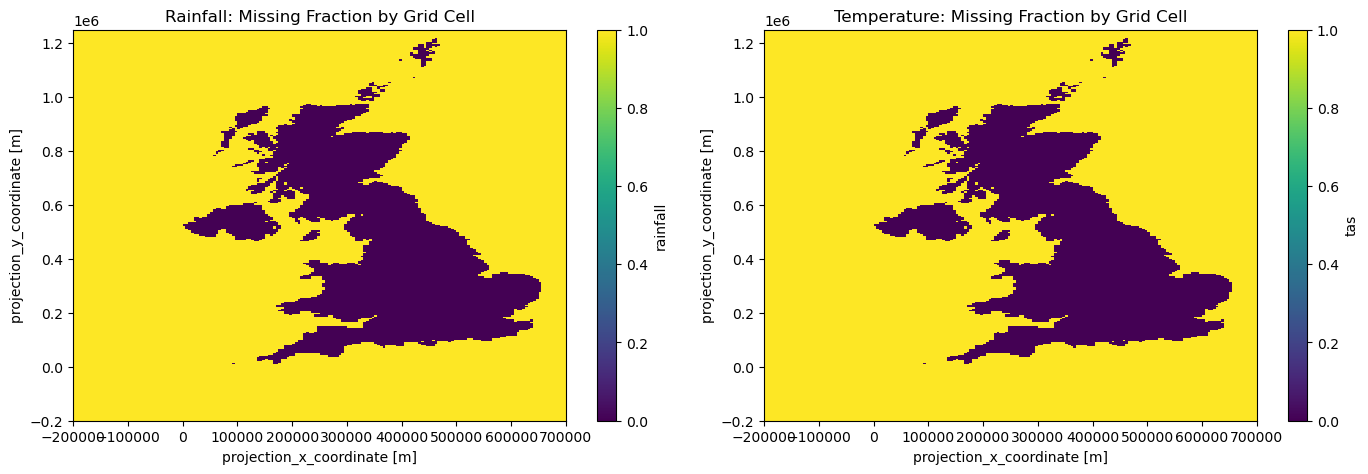

In [9]:
import matplotlib.pyplot as plt

# Plot the fraction of missing daily observations at each grid cell.
# This reveals whether missing values form geographic patterns.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rainfall_missing_fraction.plot(
    ax=axes[0],
    vmin=0,
    vmax=1,
    cmap="viridis",
    add_colorbar=True
)
axes[0].set_title("Rainfall: Missing Fraction by Grid Cell")

temperature_missing_fraction.plot(
    ax=axes[1],
    vmin=0,
    vmax=1,
    cmap="viridis",
    add_colorbar=True
)
axes[1].set_title("Temperature: Missing Fraction by Grid Cell")

plt.tight_layout()
plt.show()

#### Interpretation of Step 5

The results indicate that the missing values are spatially structured rather than randomly distributed. Both rainfall and temperature show exactly the same pattern: every grid cell is either complete on all 365 days or missing on all 365 days. No cell has intermittent gaps.

| Finding | Result |
|---|---:|
| Total grid cells | 52,200 |
| Grid cells always missing | 41,768 |
| Grid cells with complete observations | 10,432 |
| Grid cells with intermittent missing values | 0 |
| Percentage of grid cells with complete observations | 20% |

The complete cells form the outline of the British Isles land area, so the missing cells are mainly sea that falls inside the rectangular grid. This is only an approximation of the UK at this stage. HadUK-Grid uses its own land mask, which also covers the Isle of Man (not part of the UK), and many 5 km cells along the coast are partly land and partly sea. Step 8 tests the complete cells against an official UK boundary.

The identical patterns across both variables suggest that the missingness comes from the spatial grid, not from differences between the two weather variables.

### Step 6: Create a Valid-Grid Mask

The missing-value analysis shows that 41,768 grid cells have no valid observations throughout 2025, while 10,432 grid cells have complete rainfall and temperature observations.

To prevent cells without valid weather observations from affecting subsequent analysis, we will create a spatial mask that identifies grid cells with complete observations across the entire year. We will apply the same mask to both variables because their missing-value patterns are identical.

This approach preserves the original measurements in valid grid cells without imputing missing values or modifying the raw datasets. The resulting mask will also provide a consistent spatial basis for merging and further analysis.

In [10]:
# Identify grid cells with valid observations on every day of 2025.
# Requiring both variables to be complete ensures a consistent analysis grid.
valid_grid_mask = (
    rainfall_ds["rainfall"].notnull().all(dim="time")
    & temperature_ds["tas"].notnull().all(dim="time")
)

# Count the grid cells retained by the mask.
valid_grid_cells = int(valid_grid_mask.sum().compute().item())

# Count all available grid cells in the spatial domain.
total_grid_cells = valid_grid_mask.size

print("Total grid cells:", total_grid_cells)
print("Valid grid cells:", valid_grid_cells)
print("Excluded grid cells:", total_grid_cells - valid_grid_cells)
print(f"Percentage retained: {valid_grid_cells / total_grid_cells * 100:.2f}%")

Total grid cells: 52200
Valid grid cells: 10432
Excluded grid cells: 41768
Percentage retained: 19.98%


In [11]:
# Apply the spatial mask, excluding grid cells without complete observations.
rainfall_valid = rainfall_ds["rainfall"].where(valid_grid_mask)
temperature_valid = temperature_ds["tas"].where(valid_grid_mask)

# Count missing observations only within the grid cells selected by the mask.
# The mask prevents intentionally excluded cells from being counted as missing.
rainfall_missing_valid = int(
    rainfall_valid.isnull()
    .where(valid_grid_mask, False)
    .sum()
    .compute()
    .item()
)

temperature_missing_valid = int(
    temperature_valid.isnull()
    .where(valid_grid_mask, False)
    .sum()
    .compute()
    .item()
)

# Report missing observations within the retained grid cells.
print("Missing rainfall observations in valid cells:", rainfall_missing_valid)
print("Missing temperature observations in valid cells:", temperature_missing_valid)

Missing rainfall observations in valid cells: 0
Missing temperature observations in valid cells: 0



### Step 7: Merge Rainfall and Temperature into a Single Weather Dataset

Following the data audit and missing-value investigation, we confirmed that rainfall and temperature share identical temporal and spatial coordinates. We also identified 10,432 grid cells with complete observations throughout 2025. The missing-value visualizations revealed that the missing observations are concentrated in grid cells outside the UK land area. Since this project focuses exclusively on the UK, these locations are outside our area of interest and are not required for the analysis. We therefore created a spatial mask to retain grid cells with complete rainfall and temperature observations throughout 2025.

In this step, we will combine the validated rainfall and temperature variables into a single `xarray.Dataset`. We will also exclude the invalid grid cells from the resulting dataset so that subsequent analysis operates only on the retained spatial domain.

Before merging, we will verify that the time and spatial coordinates match exactly. We will then inspect the merged dataset to confirm that both variables are present and that the expected temporal coverage has been preserved.



In [12]:

# Confirm that the variables have identical time and spatial coordinates.
assert rainfall_valid.time.equals(temperature_valid.time)
assert rainfall_valid.projection_x_coordinate.equals(
    temperature_valid.projection_x_coordinate
)
assert rainfall_valid.projection_y_coordinate.equals(
    temperature_valid.projection_y_coordinate
)

# Merge both validated variables into one dataset.
# join="exact" stops xarray from silently aligning mismatched coordinates.
# combine_attrs="drop" stops the rainfall variable's attributes (e.g. units: mm)
# from being copied onto the whole dataset. Each variable keeps its own attributes.
weather_2025 = xr.merge(
    [
        rainfall_valid.rename("rainfall"),
        temperature_valid.rename("tas")
    ],
    join="exact",
    compat="no_conflicts",
    combine_attrs="drop"
)

# Restore each variable's own metadata in case the merge removed it.
weather_2025["rainfall"].attrs = dict(rainfall_ds["rainfall"].attrs)
weather_2025["tas"].attrs = dict(temperature_ds["tas"].attrs)

# Display the merged dataset's structure and metadata.
print(weather_2025)
print("\nRainfall units:", weather_2025["rainfall"].attrs.get("units"))
print("Temperature units:", weather_2025["tas"].attrs.get("units"))


<xarray.Dataset> Size: 306MB
Dimensions:                  (time: 365, projection_y_coordinate: 290,
                              projection_x_coordinate: 180)
Coordinates:
  * time                     (time) datetime64[ns] 3kB 2025-01-01T12:00:00 .....
  * projection_y_coordinate  (projection_y_coordinate) float64 2kB -1.975e+05...
  * projection_x_coordinate  (projection_x_coordinate) float64 1kB -1.975e+05...
    latitude                 (projection_y_coordinate, projection_x_coordinate) float64 418kB ...
    longitude                (projection_y_coordinate, projection_x_coordinate) float64 418kB ...
Data variables:
    rainfall                 (time, projection_y_coordinate, projection_x_coordinate) float64 152MB dask.array<chunksize=(31, 290, 180), meta=np.ndarray>
    tas                      (time, projection_y_coordinate, projection_x_coordinate) float64 152MB dask.array<chunksize=(31, 290, 180), meta=np.ndarray>

Rainfall units: mm
Temperature units: degC


In [13]:
# Confirm that both expected weather variables are present.
assert "rainfall" in weather_2025.data_vars
assert "tas" in weather_2025.data_vars

# Check that the merged dataset retains the expected time coverage.
assert weather_2025.sizes["time"] == 365
assert weather_2025.time.min().dt.year.item() == 2025
assert weather_2025.time.max().dt.year.item() == 2025

# Confirm that both variables have zero missing values within valid cells.
rainfall_missing = int(
    weather_2025["rainfall"].isnull().where(valid_grid_mask, False)
    .sum().compute().item()
)
temperature_missing = int(
    weather_2025["tas"].isnull().where(valid_grid_mask, False)
    .sum().compute().item()
)

print("Variables:", list(weather_2025.data_vars))
print("Time observations:", weather_2025.sizes["time"])
print("Valid grid cells:", int(valid_grid_mask.sum().compute().item()))
print("Missing rainfall observations in valid cells:", rainfall_missing)
print("Missing temperature observations in valid cells:", temperature_missing)

Variables: ['rainfall', 'tas']
Time observations: 365
Valid grid cells: 10432
Missing rainfall observations in valid cells: 0
Missing temperature observations in valid cells: 0


### Step 8: Obtain the Official UK Geographic Boundary

Before defining the final spatial extent of our weather analysis, we need to verify the valid HadUK-Grid cells against an authoritative geographic boundary.

We will use the Office for National Statistics (ONS) Countries (December 2025) Boundaries UK dataset, specifically the full-resolution boundary clipped to the coastline (BFC).

This boundary will provide an independent geographic reference for determining whether the grid cells with complete weather observations correspond to the UK land area. We will inspect the boundary's coordinate reference system (CRS) and compare it with the CRS used by the HadUK-Grid data before performing any spatial operations.

We will retain the original rectangular weather grid during this verification. Once the comparison is complete, we can determine whether the existing valid-grid mask is sufficient or whether a refined UK geographic mask is required.

#### Step 8.1: Load the UK Boundary and Inspect Coordinate Reference Systems

Load the downloaded GeoJSON boundary using GeoPandas and inspect its geometry, geographic coverage, and coordinate reference system.

We will also inspect the projection metadata stored in the HadUK-Grid dataset. Both datasets must use compatible coordinate reference systems before we can accurately compare the weather grid with the UK boundary.

At this stage, we will only inspect the data and coordinate systems. We will not create or apply the final geographic mask until the CRS information has been verified.

In [14]:
# Import the libraries required for loading and inspecting the UK boundary.
import geopandas as gpd
import pyogrio
from pyproj import CRS

# Define the path to the downloaded official UK boundary GeoJSON file.
boundary_path = Path("../data/boundaries/Countries_December_2025_Boundaries_UK_BFC_-2912039989678096674.geojson")

# Remove GDAL's default GeoJSON feature-size limit to support large geometries.
pyogrio.set_gdal_config_options({
    "OGR_GEOJSON_MAX_OBJ_SIZE": "0"
})

# Load the official UK boundary dataset.
uk_boundary = gpd.read_file(boundary_path)

# Inspect the boundary's coordinate reference system and geometry.
print("Boundary CRS:", uk_boundary.crs)
print("Number of boundary features:", len(uk_boundary))
print("Geometry types:", uk_boundary.geom_type.value_counts().to_dict())
print("Boundary columns:", uk_boundary.columns.tolist())

# Inspect the HadUK-Grid projection metadata.
projection_attributes = rainfall_ds["transverse_mercator"].attrs

print("\nHadUK-Grid projection attributes:")
for key, value in projection_attributes.items():
    print(f"{key}: {value}")

# Attempt to interpret the projection metadata as a CRS.
try:
    haduk_crs = CRS.from_cf(projection_attributes)
    print("\nHadUK-Grid CRS:")
    print(haduk_crs)
except Exception as error:
    print("\nCould not determine the HadUK-Grid CRS from these attributes.")
    print("Error:", error)

Boundary CRS: EPSG:27700
Number of boundary features: 4
Geometry types: {'MultiPolygon': 4}
Boundary columns: ['FID', 'CTRY25CD', 'CTRY25NM', 'CTRY25NMW', 'BNG_E', 'BNG_N', 'LONG', 'LAT', 'geometry']

HadUK-Grid projection attributes:
grid_mapping_name: transverse_mercator
longitude_of_prime_meridian: 0.0
semi_major_axis: 6377563.396
semi_minor_axis: 6356256.909
longitude_of_central_meridian: -2.0
latitude_of_projection_origin: 49.0
false_easting: 400000.0
false_northing: -100000.0
scale_factor_at_central_meridian: 0.9996012717

HadUK-Grid CRS:
{"$schema": "https://proj.org/schemas/v0.2/projjson.schema.json", "type": "ProjectedCRS", "name": "undefined", "base_crs": {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "undefined", "datum": {"type": "GeodeticReferenceFrame", "name": "undefined", "ellipsoid": {"name": "undefined", "semi_major_axis": 6377563.396, "semi_minor_axis": 6356256.909}, "prime_meridian": {"name": "undefined", "longitud

#### Step 8.2: Verify the Coordinate Reference Systems

The official ONS boundary dataset uses EPSG:27700 (British National Grid). The HadUK-Grid projection metadata contains matching Transverse Mercator parameters: the Airy 1830 ellipsoid, a central meridian of -2°, a latitude of origin of 49°, a scale factor of 0.9996012717, a false easting of 400,000 m and a false northing of -100,000 m.

The CRS built from the HadUK-Grid metadata has no EPSG code attached, but its parameters are those of British National Grid. The code below checks each parameter. It does not change the grid coordinates; it confirms that the HadUK-Grid eastings and northings can be compared directly with the ONS boundary, and later with the DfT collision coordinates, which also use British National Grid.

The CRS is carried into the saved file in Step 8.8 by keeping the original `transverse_mercator` grid-mapping variable that the data variables refer to.

In [15]:

# Define the official British National Grid coordinate reference system.
uk_crs = CRS.from_epsg(27700)

# Verify that the boundary is already in the expected CRS.
assert uk_boundary.crs.to_epsg() == 27700, (
    "The UK boundary is not in EPSG:27700."
)

# Compare each HadUK-Grid projection parameter with British National Grid.
# Tolerances are small because these are defined constants, not measurements.
expected_parameters = {
    "semi_major_axis": 6377563.396,                   # Airy 1830 ellipsoid
    "semi_minor_axis": 6356256.909,                   # Airy 1830 ellipsoid
    "longitude_of_central_meridian": -2.0,
    "latitude_of_projection_origin": 49.0,
    "scale_factor_at_central_meridian": 0.9996012717,
    "false_easting": 400000.0,
    "false_northing": -100000.0,
}

for name, expected in expected_parameters.items():
    actual = float(projection_attributes[name])
    assert abs(actual - expected) < 1e-6, f"{name}: {actual} != {expected}"
    print(f"{name:35s} {actual:>15} matches")

# These are only read here for reporting; the coordinates are not modified.
grid_x = rainfall_ds["projection_x_coordinate"]
grid_y = rainfall_ds["projection_y_coordinate"]

print("\nONS boundary CRS:", uk_boundary.crs)
print("HadUK-Grid parameters match:", uk_crs.name)
print("Grid x-coordinate range:", float(grid_x.min()), "to", float(grid_x.max()))
print("Grid y-coordinate range:", float(grid_y.min()), "to", float(grid_y.max()))


semi_major_axis                         6377563.396 matches
semi_minor_axis                         6356256.909 matches
longitude_of_central_meridian                  -2.0 matches
latitude_of_projection_origin                  49.0 matches
scale_factor_at_central_meridian       0.9996012717 matches
false_easting                              400000.0 matches
false_northing                            -100000.0 matches

ONS boundary CRS: EPSG:27700
HadUK-Grid parameters match: OSGB36 / British National Grid
Grid x-coordinate range: -197500.0 to 697500.0
Grid y-coordinate range: -197500.0 to 1247500.0


#### Step 8.3: Compare HadUK-Grid Cell Centres with the Official UK Boundary

We take the centre point of each HadUK-Grid cell from its projected x and y coordinates and test whether it lies within the official ONS UK boundary, using British National Grid (EPSG:27700).

This gives an independent geographic mask to compare with the complete-observation mask from Step 6. We count the cell centres inside the UK boundary, compare the two masks, and identify any differences. The weather dataset is not modified at this stage.

The test uses Shapely 2's vectorised `intersects_xy`, which checks all 52,200 centres in one call instead of building 52,200 separate `Point` objects. For a single point, "intersects the boundary" is the same as "is covered by the boundary", so points lying exactly on the coastline still count as inside.

In [16]:
import numpy as np
import shapely

# Extract the projected x and y coordinates from the weather grid.
grid_x = rainfall_ds["projection_x_coordinate"].values
grid_y = rainfall_ds["projection_y_coordinate"].values

# Build a centre point for every cell. meshgrid keeps the same
# y-by-x layout as the weather data, so results reshape directly onto the grid.
x_mesh, y_mesh = np.meshgrid(grid_x, grid_y)

# Combine the four ONS country polygons into one UK boundary geometry.
uk_geometry = uk_boundary.geometry.union_all()

# Preparing the geometry builds an internal spatial index, which makes the
# many point and box tests below much faster against a full-resolution coastline.
shapely.prepare(uk_geometry)

# Test every cell centre against the boundary in one vectorised call.
uk_boundary_mask = shapely.intersects_xy(uk_geometry, x_mesh, y_mesh)

# The complete-observation mask from Step 6, as a NumPy array.
valid_mask_array = valid_grid_mask.values

# Compare the two masks.
inside_uk_count = int(uk_boundary_mask.sum())
valid_count = int(valid_mask_array.sum())
inside_and_valid = int((uk_boundary_mask & valid_mask_array).sum())
inside_but_invalid = int((uk_boundary_mask & ~valid_mask_array).sum())
valid_but_outside = int((~uk_boundary_mask & valid_mask_array).sum())

print("Total grid cells:", uk_boundary_mask.size)
print("Cell centres inside UK boundary:", inside_uk_count)
print("Cells with complete weather observations:", valid_count)
print("Inside UK and complete:", inside_and_valid)
print("Inside UK but incomplete:", inside_but_invalid)
print("Complete observations outside UK boundary:", valid_but_outside)


Total grid cells: 52200
Cell centres inside UK boundary: 9790
Cells with complete weather observations: 10432
Inside UK and complete: 9775
Inside UK but incomplete: 15
Complete observations outside UK boundary: 657


#### Step 8.4: Investigate Differences Between the Geographic and Data-Completeness Masks

The comparison identified differences between the official ONS boundary mask and the existing complete-observation mask.

Of the 9,790 grid-cell centres inside the UK boundary, 9,775 have complete rainfall and temperature observations, while 15 have incomplete observations. Additionally, 657 cells with complete observations have centres outside the ONS boundary.

These differences indicate that data completeness alone should not be treated as an exact representation of the UK geographic extent. Before selecting the final analysis mask, we will inspect the spatial distribution of the discrepant cells and assess whether the differences occur near coastlines or elsewhere.

The original weather dataset and existing masks will remain unchanged during this investigation.

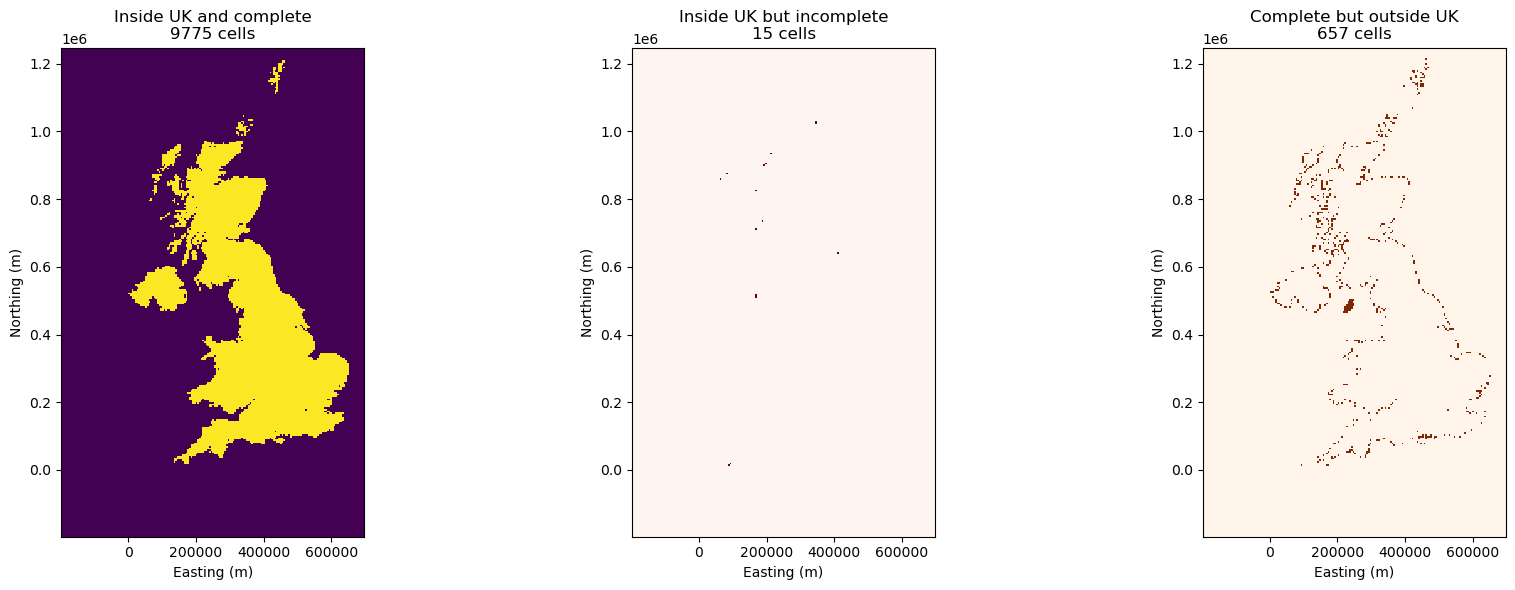

In [17]:
# Identify the three groups of cells that need to be compared.
inside_and_valid_mask = uk_boundary_mask & valid_mask_array
inside_but_invalid_mask = uk_boundary_mask & ~valid_mask_array
valid_but_outside_mask = ~uk_boundary_mask & valid_mask_array

# Display the geographic mask and the two types of discrepancy.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

plots = [
    (inside_and_valid_mask, "Inside UK and complete", "viridis"),
    (inside_but_invalid_mask, "Inside UK but incomplete", "Reds"),
    (valid_but_outside_mask, "Complete but outside UK", "Oranges"),
]

for ax, (mask, title, cmap) in zip(axes, plots):
    # Plot each mask using the original grid layout.
    ax.imshow(
        mask,
        origin="lower",
        extent=[
            grid_x.min(),
            grid_x.max(),
            grid_y.min(),
            grid_y.max(),
        ],
        interpolation="nearest",
        cmap=cmap,
        aspect="equal",
    )
    ax.set_title(f"{title}\n{int(mask.sum())} cells")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

In [18]:
# Break down the two groups of discrepant cells.
latitude = rainfall_ds["latitude"].values
longitude = rainfall_ds["longitude"].values

# A generous box around the Isle of Man. HadUK-Grid covers the island,
# but the ONS UK boundary does not, because it is a Crown Dependency.
isle_of_man = (
    (latitude > 54.0) & (latitude < 54.45)
    & (longitude > -4.9) & (longitude < -4.25)
)

valid_but_outside_mask = ~uk_boundary_mask & valid_mask_array
inside_but_invalid_mask = uk_boundary_mask & ~valid_mask_array

print("Complete cells with centres outside the UK boundary:", int(valid_but_outside_mask.sum()))
print("  of which on the Isle of Man:", int((valid_but_outside_mask & isle_of_man).sum()))
print("  of which elsewhere (coastal cells with centres at sea):",
      int((valid_but_outside_mask & ~isle_of_man).sum()))

# List the cells inside the boundary that have no weather data.
rows, cols = np.nonzero(inside_but_invalid_mask)
print("\nCells with centres inside the UK boundary but no weather data:", len(rows))
for r, c in zip(rows, cols):
    print(f"  E {grid_x[c]:>9.0f}  N {grid_y[r]:>9.0f}  "
          f"lat {latitude[r, c]:.3f}  lon {longitude[r, c]:.3f}")


Complete cells with centres outside the UK boundary: 657
  of which on the Isle of Man: 32
  of which elsewhere (coastal cells with centres at sea): 625

Cells with centres inside the UK boundary but no weather data: 15
  E     87500  N     12500  lat 49.930  lon -6.355
  E     92500  N     17500  lat 49.978  lon -6.290
  E    167500  N    512500  lat 54.454  lon -5.587
  E    167500  N    517500  lat 54.499  lon -5.591
  E    412500  N    642500  lat 55.676  lon -1.801
  E    167500  N    712500  lat 56.248  lon -5.753
  E    187500  N    737500  lat 56.482  lon -5.451
  E    167500  N    827500  lat 57.279  lon -5.858
  E     62500  N    862500  lat 57.527  lon -7.640
  E     82500  N    877500  lat 57.675  lon -7.327
  E    192500  N    902500  lat 57.964  lon -5.508
  E    197500  N    907500  lat 58.011  lon -5.428
  E    212500  N    937500  lat 58.286  lon -5.199
  E    347500  N   1027500  lat 59.131  lon -2.917
  E    347500  N   1032500  lat 59.176  lon -2.919



#### Interpretation of Step 8.4

The 657 complete cells with centres outside the ONS boundary fall into two groups. The Isle of Man cells are real land with valid HadUK-Grid data, but the island is not part of the UK, so they are correctly excluded. The rest sit along the coastline: they are 5 km squares that are partly land, but their centre point happens to fall in the sea.

The 15 cells with centres inside the boundary but no weather data are coastal slivers and small islands where the ONS boundary includes land that the HadUK-Grid land mask does not. The list above gives their locations.


The second group matters for this project. Road collisions are recorded as points, and many happen on coastal roads and in seaside towns. If a coastal cell is dropped because its centre is at sea, every collision inside it loses its weather data. Step 8.5 therefore tests whether any part of each cell overlaps the UK, not just its centre.



#### Step 8.5: Test Whether Each Cell Overlaps the UK Boundary

The centre-point test treats each 5 km cell as a single point. A cell that is 40% land but has its centre at sea is excluded, even though HadUK-Grid supplies valid weather for it and collisions can occur on its land portion.

Here we test each cell as a 5 km square instead. A cell is geographically included if any part of the square overlaps the ONS UK boundary. We then compare this overlap mask with the centre-point mask from Step 8.3.


In [19]:
# Cell size from the grid spacing (5,000 m for HadUK-Grid 5 km).
cell_size = float(grid_x[1] - grid_x[0])
half_cell = cell_size / 2

# Check the spacing is uniform in both directions before relying on it.
assert np.allclose(np.diff(grid_x), cell_size)
assert np.allclose(np.diff(grid_y), cell_size)

# Build a square for every cell, centred on its coordinates.
cell_boxes = shapely.box(
    x_mesh - half_cell, y_mesh - half_cell,
    x_mesh + half_cell, y_mesh + half_cell,
)

# A cell is included if any part of its square overlaps the UK boundary.
uk_overlap_mask = shapely.intersects(uk_geometry, cell_boxes)

overlap_and_valid = uk_overlap_mask & valid_mask_array
centre_and_valid = uk_boundary_mask & valid_mask_array

# Cells gained: complete, overlapping the UK, but with the centre at sea.
coastal_gained = overlap_and_valid & ~uk_boundary_mask

print("Cells overlapping the UK boundary:", int(uk_overlap_mask.sum()))
print("Complete cells, centre inside UK (Step 8.3):", int(centre_and_valid.sum()))
print("Complete cells, any overlap with UK:", int(overlap_and_valid.sum()))
print("Coastal cells gained by the overlap test:", int(coastal_gained.sum()))
print("Cells overlapping UK but with no weather data:",
      int((uk_overlap_mask & ~valid_mask_array).sum()))

# The overlap test must keep every cell the centre test kept.
assert not (centre_and_valid & ~overlap_and_valid).any()


Cells overlapping the UK boundary: 11158
Complete cells, centre inside UK (Step 8.3): 9775
Complete cells, any overlap with UK: 10400
Coastal cells gained by the overlap test: 625
Cells overlapping UK but with no weather data: 758


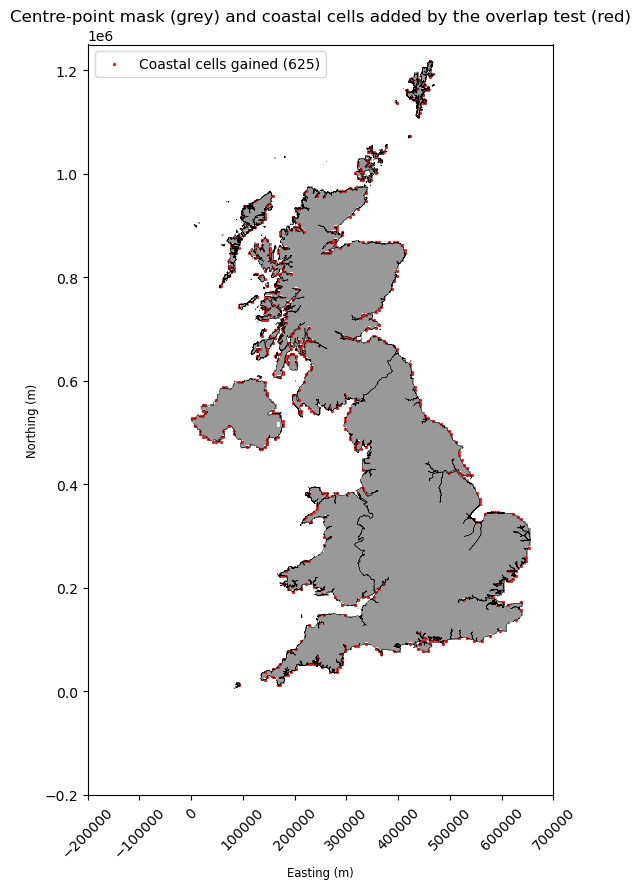

In [22]:
# Show the coastal cells gained by the overlap test.
fig, ax = plt.subplots(figsize=(7, 9))

ax.imshow(
    centre_and_valid,
    origin="lower",
    extent=[grid_x.min() - half_cell, grid_x.max() + half_cell,
            grid_y.min() - half_cell, grid_y.max() + half_cell],
    interpolation="nearest",
    cmap="Greys",
    alpha=0.4,
)
gained_rows, gained_cols = np.nonzero(coastal_gained)
ax.scatter(grid_x[gained_cols], grid_y[gained_rows], s=2, color="tab:red",
           label=f"Coastal cells gained ({int(coastal_gained.sum())})")
uk_boundary.boundary.plot(ax=ax, linewidth=0.3, color="black")

ax.set_title("Centre-point mask (grey) and coastal cells added by the overlap test (red)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()



#### Step 8.6: Check How Many Road Collisions Each Mask Would Keep

The weather grid will be joined to the DfT road collision data, so the choice of mask should be judged by how many collisions it leaves without weather data. The DfT collision coordinates are also British National Grid eastings and northings, so each collision can be placed in a HadUK-Grid cell by arithmetic alone.

This step only reads the collision coordinates. The full audit of the road data is carried out in notebook 02.


In [23]:
import pandas as pd

# dir containing the collision data.
collision_path = Path("../data/incident/dft-road-casualty-statistics-collision-2025.csv")

collisions = pd.read_csv(
    collision_path,
    usecols=["collision_index", "location_easting_osgr", "location_northing_osgr"],
)
total_collisions = len(collisions)

# Two collisions have no recorded location; they cannot be placed on the grid.
collisions = collisions.dropna(subset=["location_easting_osgr", "location_northing_osgr"])
print("Collisions:", total_collisions)
print("Collisions without coordinates:", total_collisions - len(collisions))

# Convert each easting and northing into a row and column index on the grid.
# Cell edges start half a cell below the first centre (e.g. -200,000 m).
col_index = np.floor(
    (collisions["location_easting_osgr"].to_numpy() - (grid_x[0] - half_cell)) / cell_size
).astype(int)
row_index = np.floor(
    (collisions["location_northing_osgr"].to_numpy() - (grid_y[0] - half_cell)) / cell_size
).astype(int)

on_grid = (
    (col_index >= 0) & (col_index < len(grid_x))
    & (row_index >= 0) & (row_index < len(grid_y))
)
print("Collisions outside the weather grid:", int((~on_grid).sum()))

r, c = row_index[on_grid], col_index[on_grid]
n = len(collisions)

def report(label, mask):
    kept = int(mask[r, c].sum())
    print(f"{label:45s} {kept:>7,} kept   {n - kept:>6,} lost ({100 * (n - kept) / n:.2f}%)")

print()
report("Complete observations only (Step 6)", valid_mask_array)
report("Centre inside UK + complete (Step 8.3)", centre_and_valid)
report("Overlaps UK + complete (Step 8.5)", overlap_and_valid)

no_weather = ~valid_mask_array[r, c]
print("\nCollisions in cells with no weather data at all:", int(no_weather.sum()))


Collisions: 101525
Collisions without coordinates: 2
Collisions outside the weather grid: 0

Complete observations only (Step 6)           101,255 kept      268 lost (0.26%)
Centre inside UK + complete (Step 8.3)         97,952 kept    3,571 lost (3.52%)
Overlaps UK + complete (Step 8.5)             101,255 kept      268 lost (0.26%)

Collisions in cells with no weather data at all: 268



#### Interpretation of Step 8.6


The overlap mask can only keep more collisions than the centre-point mask, because it keeps every cell the centre-point mask keeps and adds the coastal cells. The collisions that remain unmatched under both masks fall in cells where HadUK-Grid supplies no data at all (coastal slivers outside its land mask). Notebook 03 will either assign those collisions to the nearest cell with data or report them as a limitation.



#### Step 8.7: Define the Final UK Weather Analysis Mask

The final analysis mask combines two conditions:
1. Some part of the 5 km cell overlaps the official ONS UK boundary (Step 8.5).
2. Both rainfall and temperature are complete for all 365 days of 2025 (Step 6).

The overlap test is used instead of the centre-point test because the weather data will be matched to collisions, which are points: any cell containing land can contain a collision. The Isle of Man is still excluded because no part of it lies inside the ONS UK boundary.

Coastal cells added by the overlap test are flagged separately (`coastal_cell`), so later analysis can check whether results change when they are excluded.

The original rectangular grid is preserved, with excluded cells set to missing.


In [24]:
grid_coords = {
    "projection_y_coordinate": rainfall_ds["projection_y_coordinate"],
    "projection_x_coordinate": rainfall_ds["projection_x_coordinate"],
}
grid_dims = ["projection_y_coordinate", "projection_x_coordinate"]

# Geographic mask: cell overlaps the UK boundary.
uk_geographic_mask = xr.DataArray(uk_overlap_mask, coords=grid_coords, dims=grid_dims)

# Final mask: overlaps the UK and has complete observations.
final_analysis_mask = (uk_geographic_mask & valid_grid_mask).compute()
final_analysis_mask.name = "analysis_mask"

# Flag the coastal cells whose centre lies outside the boundary.
coastal_cell_mask = final_analysis_mask & xr.DataArray(
    ~uk_boundary_mask, coords=grid_coords, dims=grid_dims
)
coastal_cell_mask.name = "coastal_cell"

final_cell_count = int(final_analysis_mask.sum().item())
coastal_cell_count = int(coastal_cell_mask.sum().item())

print("Cells overlapping UK boundary:", int(uk_overlap_mask.sum()))
print("Cells with complete weather observations:", valid_count)
print("Cells retained for analysis:", final_cell_count)
print("  of which coastal (centre outside boundary):", coastal_cell_count)

# Apply the final mask without changing the original weather dataset.
rainfall_uk = weather_2025["rainfall"].where(final_analysis_mask)
temperature_uk = weather_2025["tas"].where(final_analysis_mask)

# Verify that no missing observations remain within the selected cells.
rainfall_missing_final = int(
    rainfall_uk.isnull().where(final_analysis_mask, False).sum().compute().item()
)
temperature_missing_final = int(
    temperature_uk.isnull().where(final_analysis_mask, False).sum().compute().item()
)

# Check the logic rather than a fixed number, so the check still holds
# if the boundary file or HadUK-Grid version changes.
assert final_cell_count == int(overlap_and_valid.sum())
assert coastal_cell_count == int(coastal_gained.sum())
assert rainfall_missing_final == 0
assert temperature_missing_final == 0

print("Missing rainfall observations in retained cells:", rainfall_missing_final)
print("Missing temperature observations in retained cells:", temperature_missing_final)


Cells overlapping UK boundary: 11158
Cells with complete weather observations: 10432
Cells retained for analysis: 10400
  of which coastal (centre outside boundary): 625
Missing rainfall observations in retained cells: 0
Missing temperature observations in retained cells: 0



#### Step 8.8: Save the Final Masked Weather Dataset

We combine the masked rainfall and temperature variables into one dataset and save it in NetCDF format, keeping the time dimension, projected coordinates, latitude and longitude, and variable metadata on the original rectangular grid.

Three additions make the file self-contained for later notebooks:
- **`transverse_mercator`**: the grid-mapping variable that `rainfall` and `tas` refer to. Without it, the file's CRS reference points to nothing.
- **`analysis_mask`** and **`coastal_cell`**: stored as 0/1 integers, so notebook 03 can use them without rebuilding the boundary test.
- **Compression**: about 80% of the grid is missing (sea), so zlib compression greatly reduces the file size without changing any values.


In [25]:
# Combine the masked weather variables into one dataset.
weather_uk_2025 = xr.Dataset(
    {
        "rainfall": rainfall_uk,
        "tas": temperature_uk,
    }
)
weather_uk_2025["rainfall"].attrs = dict(rainfall_ds["rainfall"].attrs)
weather_uk_2025["tas"].attrs = dict(temperature_ds["tas"].attrs)

# Store the masks as 0/1 integers (NetCDF has no boolean type).
weather_uk_2025["analysis_mask"] = final_analysis_mask.astype("int8")
weather_uk_2025["analysis_mask"].attrs = {
    "long_name": "Cell retained for analysis",
    "description": "1 = cell overlaps the ONS UK boundary and has complete "
                   "rainfall and tas observations for all of 2025; 0 = excluded",
}
weather_uk_2025["coastal_cell"] = coastal_cell_mask.astype("int8")
weather_uk_2025["coastal_cell"].attrs = {
    "long_name": "Coastal cell",
    "description": "1 = retained cell whose centre lies outside the ONS UK "
                   "boundary (partly land, partly sea); 0 = otherwise",
}

# Keep the grid-mapping variable so the CRS travels with the file.
# open_mfdataset may have repeated it along time; one copy is enough.
crs_variable = rainfall_ds["transverse_mercator"]
if "time" in crs_variable.dims:
    crs_variable = crs_variable.isel(time=0, drop=True)
weather_uk_2025["transverse_mercator"] = crs_variable.load()

# Dataset-level metadata.
weather_uk_2025.attrs = {
    "title": "UK Daily Rainfall and Mean Temperature, 2025",
    "source": "Met Office HadUK-Grid, 5 km daily rainfall and tas",
    "geographic_boundary": "ONS Countries (December 2025) Boundaries UK BFC",
    "crs": "EPSG:27700 (British National Grid)",
    "valid_grid_cells": final_cell_count,
    "coastal_grid_cells": coastal_cell_count,
    "description": (
        "Daily rainfall and mean air temperature (mid-range of Tmax and Tmin) "
        "for 5 km grid cells that overlap the ONS UK boundary and have "
        "complete observations throughout 2025. Excluded cells are NaN."
    ),
}

# Clear encodings inherited from the source files, then compress the
# weather variables. Compression is lossless; values are unchanged.
for variable in weather_uk_2025.variables.values():
    variable.encoding = {}

encoding = {
    v: {"zlib": True, "complevel": 4}
    for v in ["rainfall", "tas", "analysis_mask", "coastal_cell"]
}

# Create the output directory if it does not already exist.
output_dir = Path("../data/weather/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the validated dataset in NetCDF format.
output_path = output_dir / "uk_weather_2025_masked.nc"
weather_uk_2025.to_netcdf(output_path, encoding=encoding)

print("Saved dataset:", output_path)
print(f"File size: {output_path.stat().st_size / 1e6:.1f} MB")
print("Dimensions:", dict(weather_uk_2025.sizes))
print("Variables:", list(weather_uk_2025.data_vars))
print("Retained grid cells:", final_cell_count)


Saved dataset: ..\data\weather\processed\uk_weather_2025_masked.nc
File size: 71.5 MB
Dimensions: {'time': 365, 'projection_y_coordinate': 290, 'projection_x_coordinate': 180}
Variables: ['rainfall', 'tas', 'analysis_mask', 'coastal_cell', 'transverse_mercator']
Retained grid cells: 10400



### Step 9: Reload and Verify the Saved File

A final check that the saved file can be reopened on its own and that the CRS, masks, units and values survived the save. Notebooks 02 and 03 will start from this file.


In [26]:
with xr.open_dataset(output_path) as saved:
    # The CRS can be rebuilt from the saved grid-mapping variable.
    saved_crs = CRS.from_cf(saved["transverse_mercator"].attrs)
    assert saved["rainfall"].attrs["grid_mapping"] == "transverse_mercator"

    # Mask counts match what was computed above.
    saved_mask = saved["analysis_mask"].astype(bool)
    assert int(saved_mask.sum()) == final_cell_count
    assert int(saved["coastal_cell"].sum()) == coastal_cell_count

    # Inside the mask there are no gaps; outside the mask everything is NaN.
    for v in ["rainfall", "tas"]:
        assert int(saved[v].isnull().where(saved_mask, False).sum()) == 0
        assert int(saved[v].notnull().where(~saved_mask, False).sum()) == 0

    # Units survived the save.
    assert saved["rainfall"].attrs["units"] == "mm"
    assert saved["tas"].attrs["units"] == "degC"

    # Values are unchanged by compression.
    xr.testing.assert_equal(saved["rainfall"].load(), weather_uk_2025["rainfall"].load())

    print("CRS rebuilt from file:", saved_crs.coordinate_operation.method_name)
    print("Retained cells:", int(saved_mask.sum()))
    print("Time steps:", saved.sizes["time"])
    print("All checks on the saved file passed.")


CRS rebuilt from file: Transverse Mercator
Retained cells: 10400
Time steps: 365
All checks on the saved file passed.
